In [15]:
import json
import os
import cv2
import matplotlib.pyplot as plt
import numpy as np

In [16]:
meta_path = os.path.join("..", "data", "sample_annotations.json")
with open(meta_path, "r", encoding="utf-8") as f:
    dev_ids = json.load(f)["dev_ids"]

images_dir = os.path.join("..", "data", "sample_images")
dev_images = {
    idx: cv2.imread(os.path.join(images_dir, f"{idx}.png")) for idx in dev_ids
}

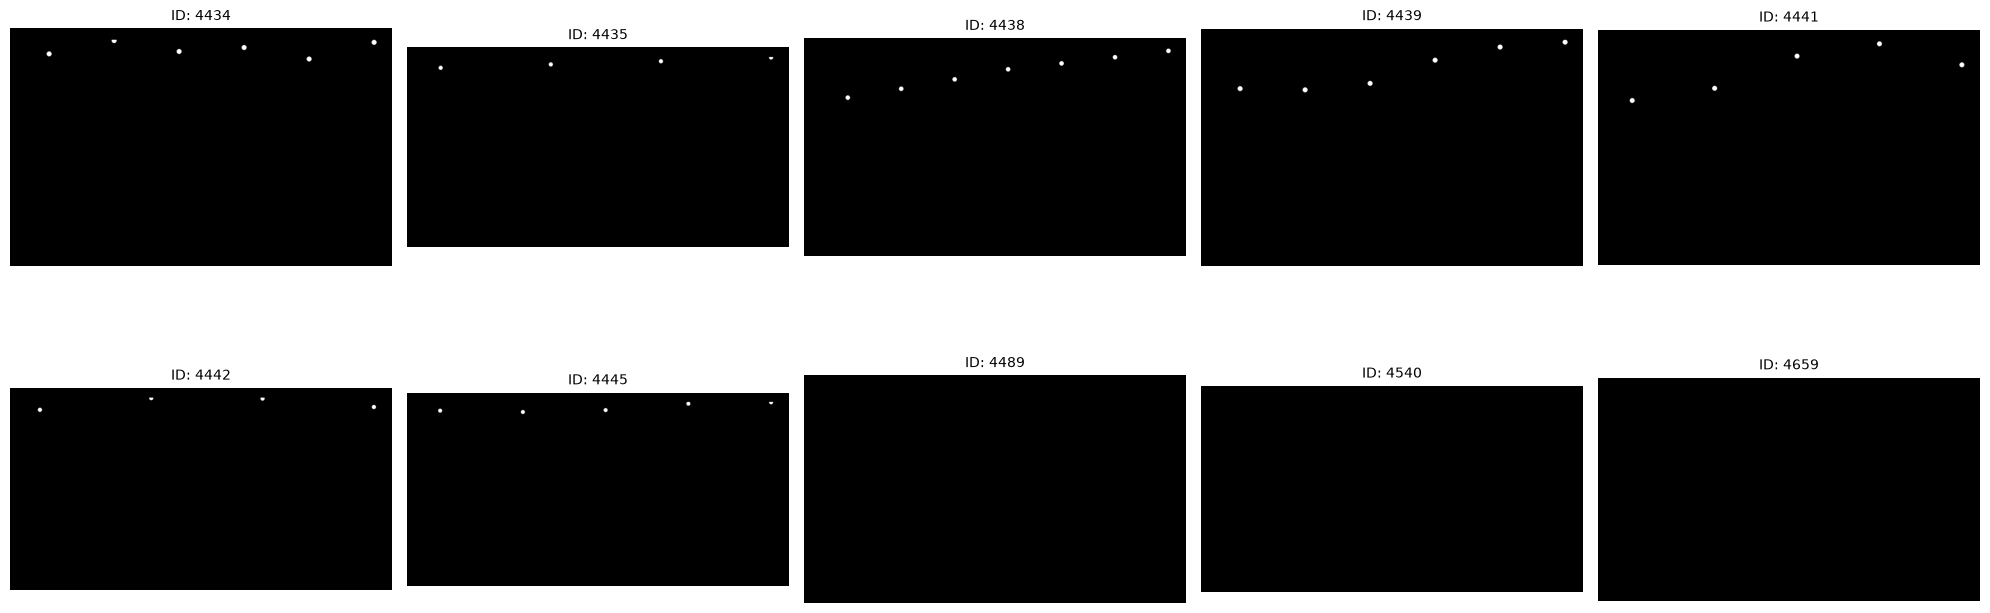

In [17]:
rows, cols = 2, 5
fig, axes = plt.subplots(rows, cols, figsize=(20, 8))
axes = axes.flatten()

for i, dev_id in enumerate(dev_ids):
    ax = axes[i]
    img = dev_images.get(dev_id)

    if img is not None:
        hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

        saturation_channel = hsv[:, :, 1]

        ax.imshow(saturation_channel, cmap="gray")
        ax.set_title(f"ID: {dev_id}", fontsize=10)
    else:
        ax.text(0.5, 0.5, "Brak", ha="center", va="center")

    ax.axis("off")

for j in range(len(dev_ids), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

wiemy, ze kropki szare, biale, czarne mają nasycenie zblizone do zera, wiec w skali szarosci wszystko sie ze sobą zlewa i komputer nie wykryje kropek

ze to kropki kolorowe zostaly wyodrębnione idealnie, a wszystkie napisy i siatki zniknęły, dlatego do kolorowych kropek bedziemy uzywac BGR2HSV.

teraz musimy rozwiazac problem kropek o minimalnym nasyceniu

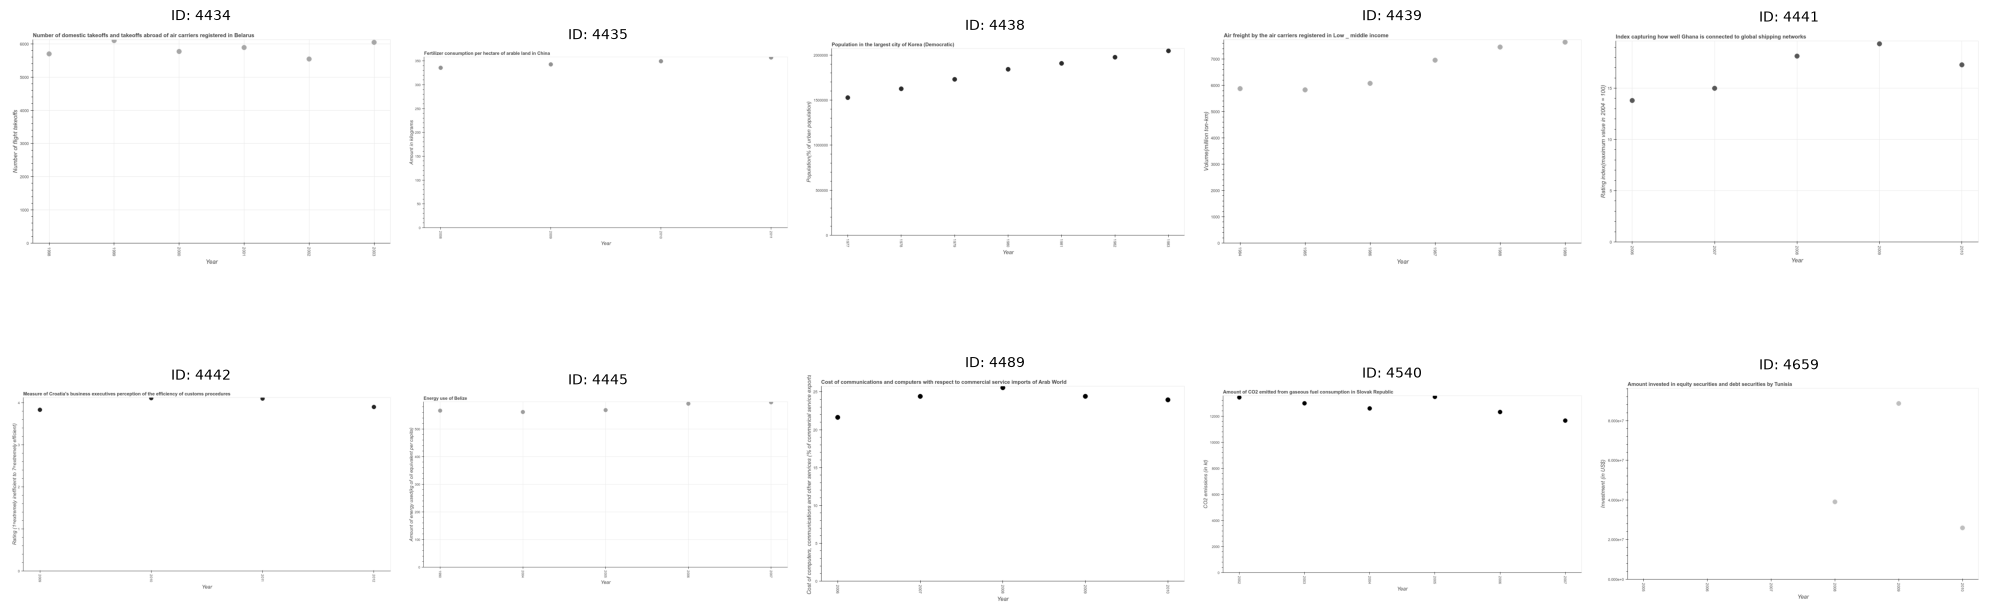

In [18]:
rows, cols = 2, 5
fig, axes = plt.subplots(rows, cols, figsize=(20, 8))
axes = axes.flatten()

for i, dev_id in enumerate(dev_ids):
    ax = axes[i]
    img = dev_images.get(dev_id)

    if img is not None:
        gray_img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

        ax.imshow(gray_img, cmap="gray")
        ax.set_title(f"ID: {dev_id}", fontsize=10)
    else:
        ax.text(0.5, 0.5, "Brak", ha="center", va="center")

    ax.axis("off")

for j in range(len(dev_ids), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

teraz sprawdzamy, dla jakiej granicy, komputer uzna, ze wykres jest monochromatyczny

[4489, 4540, 4659]


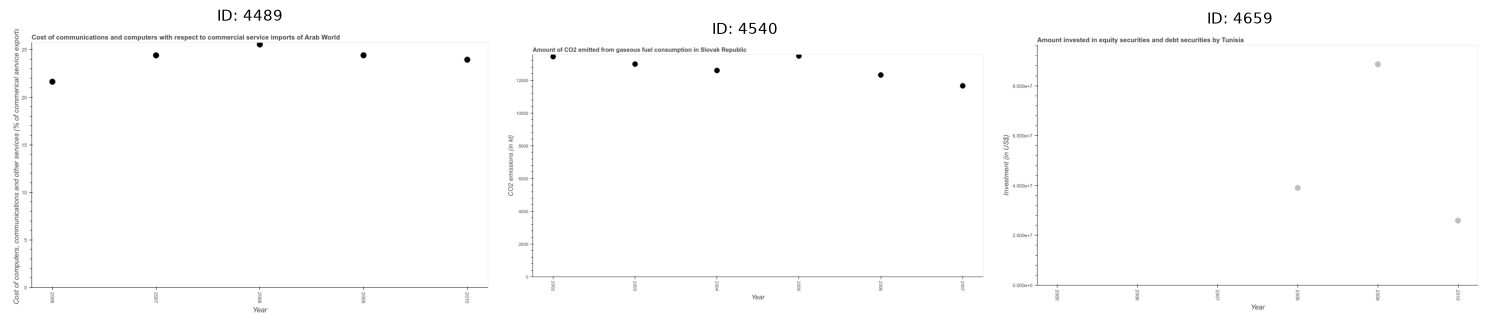

In [19]:
def is_monochrome(img, sat_max_threshold=40):
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    max_sat = hsv[:, :, 1].max()
    return max_sat < sat_max_threshold


mono_ids = [
    dev_id for dev_id in dev_ids if is_monochrome(dev_images[dev_id])
]


print(mono_ids)  

fig, axes = plt.subplots(1, len(mono_ids), figsize=(15, 5))
for ax, dev_id in zip(axes, mono_ids):
    gray = cv2.cvtColor(dev_images[dev_id], cv2.COLOR_BGR2GRAY)
    ax.imshow(gray, cmap="gray")
    ax.set_title(f"ID: {dev_id}", fontsize=11)
    ax.axis("off")

plt.tight_layout()
plt.show()

dla metody BGR2GRAY nie widzimy gołym okiem na razie róznicy, bo wykresy wygladaja identycznie przed, jak i po przeksztalceniu, ale za to komputer otrzymuje jednowymiarową macierz jasności, które przyda się nam do progowania adaptacyjnego, które wyizoluje czarne i szare kropki, zobaczmy jak to zadziala

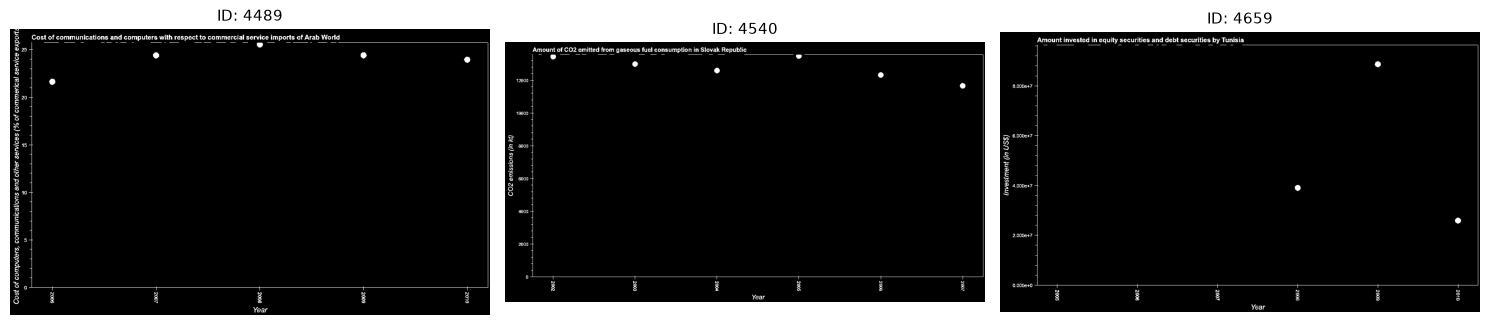

In [20]:
fig, axes = plt.subplots(1, len(mono_ids), figsize=(15, 5))

if len(mono_ids) == 1:
    axes = [axes]

for ax, dev_id in zip(axes, mono_ids):
    img = dev_images[dev_id]
        
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    thresh = cv2.adaptiveThreshold(
        gray,
        255,
        cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
        cv2.THRESH_BINARY_INV,
        blockSize=25,
        C=12
    )

    ax.imshow(thresh, cmap='gray')
    ax.set_title(f"ID: {dev_id}", fontsize=11)
    ax.axis("off")

plt.tight_layout()
plt.show()

jak widzimy, progowanie nam ladnie odcielo wszystkie kropki i teraz napewno bedzie mniejszy klopot z ich dokladnym rozpoznaniem, ale problemem sa widoczne osie wykresu oraz napisy. Dazymy do tego, aby na wykresie zostaly same kropki, zeby programowi bylo latwo je odczytac 

sprobujemy do tego transformacje Hougha dla okręgów

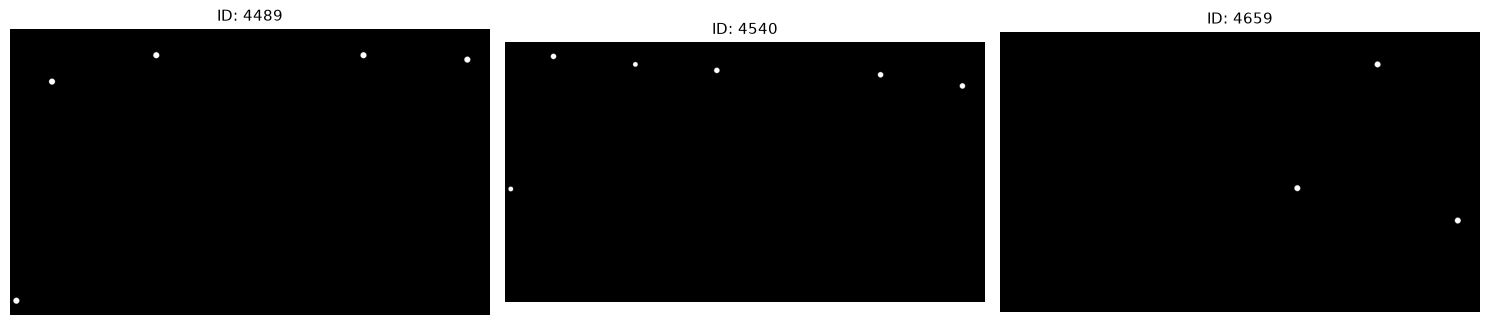

In [21]:
fig, axes = plt.subplots(1, len(mono_ids), figsize=(15, 5))
if len(mono_ids) == 1:
    axes = [axes]

for ax, dev_id in zip(axes, mono_ids):
    img = dev_images[dev_id]
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    blurred = cv2.GaussianBlur(gray, (5, 5), 0)

    circles = cv2.HoughCircles(
        blurred,
        cv2.HOUGH_GRADIENT,
        dp=1.2,
        minDist=35, 
        param1=50, 
        param2=25, 
        minRadius=5, 
        maxRadius=12,
    )

    clean_mask = np.zeros_like(gray)

    if circles is not None:
        circles = np.uint16(np.around(circles))
        for i in circles[0, :]:
            cv2.circle(clean_mask, (i[0], i[1]), i[2], 255, -1)

    ax.imshow(clean_mask, cmap="gray")
    ax.set_title(f"ID: {dev_id}", fontsize=11)
    ax.axis("off")

plt.tight_layout()
plt.show()

jak widzimy, ta metoda nie przynosi nam oczekiwanych rezultatow, faktycznie wykrywa kropki, ale dodatkowo tez nie te, ktore bysmy chcieli. Ciezko by bylo dostosowac parametry tak, abysmy mieli za kazdym razem pewnosc, ze wykrył to, co nas interesuje

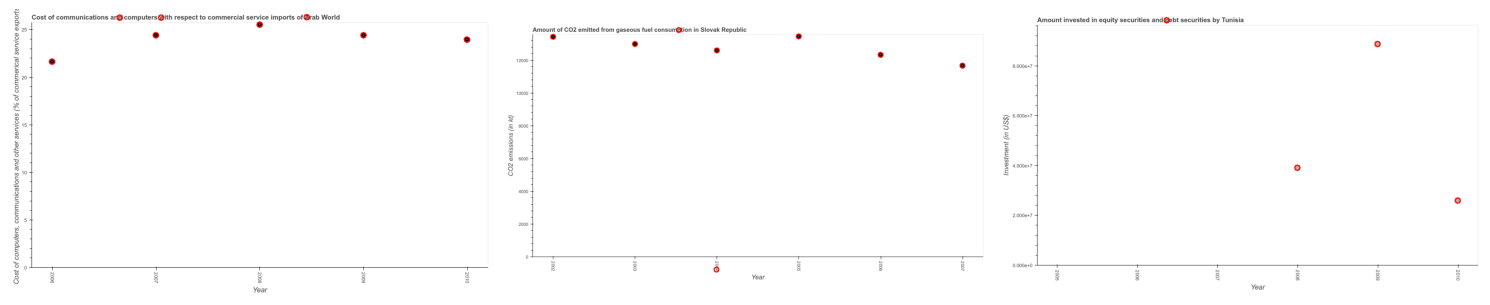

In [22]:
fig, axes = plt.subplots(1, len(mono_ids), figsize=(15, 5))
if len(mono_ids) == 1:
    axes = [axes]

for ax, dev_id in zip(axes, mono_ids):
    img = dev_images[dev_id].copy()
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    thresh = cv2.adaptiveThreshold(
        gray,
        255,
        cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
        cv2.THRESH_BINARY_INV,
        blockSize=15,
        C=3,
    )

    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    thresh_clean = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel, iterations=1)

    contours, _ = cv2.findContours(
        thresh_clean, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )

    dots_mask = np.zeros_like(gray)
    detected_centers = []

    for c in contours:
        area = cv2.contourArea(c)
        perimeter = cv2.arcLength(c, True)

        if perimeter == 0:
            continue

        x, y, w, h = cv2.boundingRect(c)
        aspect_ratio = float(w) / h if h > 0 else 0
        circularity = (4 * np.pi * area) / (perimeter**2)


        if (
            15 <= area <= 450
            and circularity >= 0.35
            and 0.65 <= aspect_ratio <= 1.45
        ):
            cv2.drawContours(dots_mask, [c], -1, 255, -1)

            M = cv2.moments(c)
            if M["m00"] != 0:
                cx = int(M["m10"] / M["m00"])
                cy = int(M["m01"] / M["m00"])
                detected_centers.append((cx, cy))

    img_result = img.copy()
    for cx, cy in detected_centers:
        cv2.circle(img_result, (cx, cy), 6, (0, 0, 255), 2)
        cv2.circle(img_result, (cx, cy), 1, (0, 255, 0), -1)

    ax.imshow(cv2.cvtColor(img_result, cv2.COLOR_BGR2RGB))
    ax.axis("off")


plt.tight_layout()
plt.show()

jak widac, dalej kropki sa rozpoznawane na osi, jak i na górnej nazwie wykresu

moze byc to spowodowane tym, ze kropki niewiele roznia sie rozmiarem od pozostalych elementow


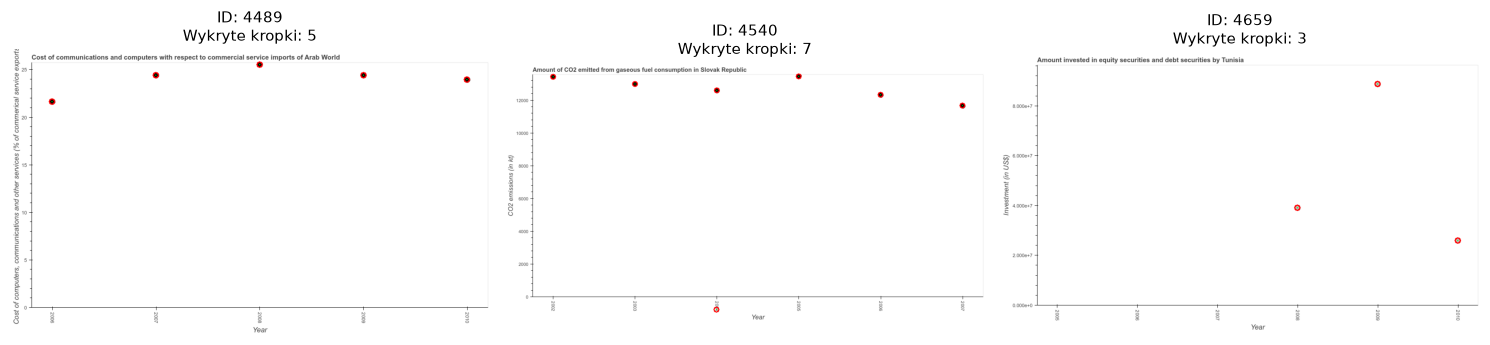

In [23]:
fig, axes = plt.subplots(1, len(mono_ids), figsize=(15, 5))
if len(mono_ids) == 1:
    axes = [axes]

for ax, dev_id in zip(axes, mono_ids):
    img = dev_images[dev_id].copy()
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    thresh = cv2.adaptiveThreshold(
        gray,
        255,
        cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
        cv2.THRESH_BINARY_INV,
        blockSize=15,
        C=3,
    )

    hor_kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (20, 1))
    horizontal_lines = cv2.morphologyEx(
        thresh, cv2.MORPH_OPEN, hor_kernel, iterations=1
    )

    y_indices, _ = np.where(horizontal_lines > 0)

    if len(y_indices) > 0:
        top_grid_y = np.min(y_indices)
        thresh[0 : max(0, top_grid_y - 2), :] = 0

    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    thresh_clean = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel, iterations=1)

    contours, _ = cv2.findContours(
        thresh_clean, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )
    detected_centers = []

    for c in contours:
        area = cv2.contourArea(c)
        perimeter = cv2.arcLength(c, True)

        if perimeter == 0:
            continue

        x, y, bw, bh = cv2.boundingRect(c)
        aspect_ratio = float(bw) / bh if bh > 0 else 0
        circularity = (4 * np.pi * area) / (perimeter**2)

        if (
            15 <= area <= 350
            and circularity >= 0.40
            and 0.70 <= aspect_ratio <= 1.40
        ):
            M = cv2.moments(c)
            if M["m00"] != 0:
                cx = int(M["m10"] / M["m00"])
                cy = int(M["m01"] / M["m00"])
                detected_centers.append((cx, cy))

    img_result = img.copy()
    for cx, cy in detected_centers:
        cv2.circle(img_result, (cx, cy), 6, (0, 0, 255), 2)
        cv2.circle(img_result, (cx, cy), 1, (0, 255, 0), -1)

    ax.imshow(cv2.cvtColor(img_result, cv2.COLOR_BGR2RGB))
    ax.set_title(
        f"ID: {dev_id}\nWykryte kropki: {len(detected_centers)}", fontsize=11
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

dzięki znaleznieniu górnej krawędzi obszaru samego wykresu, udalo się zapobiec wykrywaniu kropek na nazwie wykresu. Zatem zostajemy przy tej metodzie i probujemy znalezc reszte ograniczeń

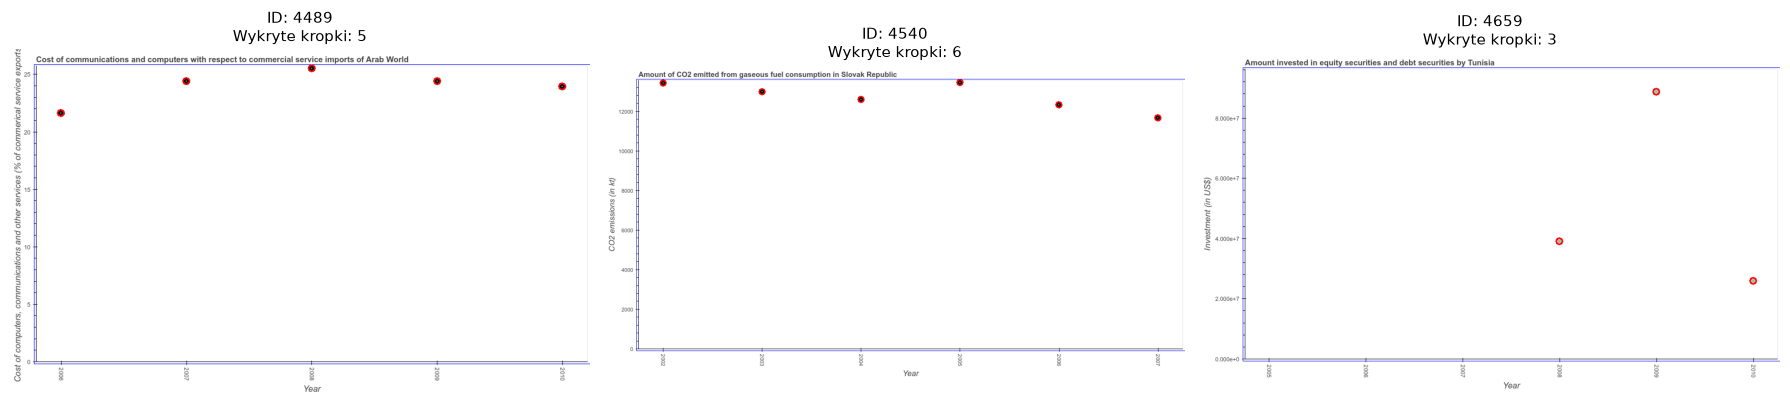

In [24]:
fig, axes = plt.subplots(1, len(mono_ids), figsize=(18, 6))
if len(mono_ids) == 1:
    axes = [axes]

for ax, dev_id in zip(axes, mono_ids):
    img = dev_images[dev_id].copy()
    h, w, _ = img.shape
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    thresh = cv2.adaptiveThreshold(
        gray,
        255,
        cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
        cv2.THRESH_BINARY_INV,
        blockSize=15,
        C=3,
    )

    hor_kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (20, 1))
    horizontal_lines = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, hor_kernel, iterations=1)
    y_indices, _ = np.where(horizontal_lines > 0)

    if len(y_indices) > 0:
        top_grid_y = np.min(y_indices)
        thresh[0:max(0, top_grid_y - 2), :] = 0
        
        bottom_grid_y = np.max(y_indices)
        thresh[min(h, bottom_grid_y + 4):, :] = 0

    ver_kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (1, 20))
    vertical_lines = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, ver_kernel, iterations=1)
    _, x_indices = np.where(vertical_lines > 0)

    if len(x_indices) > 0:
        left_grid_x = np.min(x_indices)
        thresh[:, 0:max(0, left_grid_x - 4)] = 0

    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    thresh_clean = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel, iterations=1)

    contours, _ = cv2.findContours(
        thresh_clean, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )
    detected_centers = []

    for c in contours:
        area = cv2.contourArea(c)
        perimeter = cv2.arcLength(c, True)

        if perimeter == 0:
            continue

        x, y, bw, bh = cv2.boundingRect(c)
        aspect_ratio = float(bw) / bh if bh > 0 else 0
        circularity = (4 * np.pi * area) / (perimeter**2)

        if (
            15 <= area <= 350
            and circularity >= 0.40
            and 0.65 <= aspect_ratio <= 1.45
        ):
            M = cv2.moments(c)
            if M["m00"] != 0:
                cx = int(M["m10"] / M["m00"])
                cy = int(M["m01"] / M["m00"])
                detected_centers.append((cx, cy))

    img_result = img.copy()

    if len(y_indices) > 0 and len(x_indices) > 0:
        cv2.rectangle(img_result, (left_grid_x - 4, top_grid_y - 2), 
                      (w, bottom_grid_y + 4), (255, 0, 0), 1)

    for cx, cy in detected_centers:
        cv2.circle(img_result, (cx, cy), 6, (0, 0, 255), 2)
        cv2.circle(img_result, (cx, cy), 1, (0, 255, 0), -1)

    ax.imshow(cv2.cvtColor(img_result, cv2.COLOR_BGR2RGB))
    ax.set_title(
        f"ID: {dev_id}\nWykryte kropki: {len(detected_centers)}", fontsize=11
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

no i udalo sie osiagnac zamierzony efekt

udalo sie wyciagnac poziome i pionowe osie wykresu, odsunelam troche granice, aby program mial mozliwosc wykrycia kropek, które są bardzo blisko osi
wszystko co lezy poza tymi granicami zostalo obcięte

pozostalosci siatki usunelam mala elipsa, a z reszty obietkow wyznaczylam tylko te, ktore maja ksztalt i wymiary kropki



teraz sprawdźmy, jak komputer sobie poradzi z wykryciem kropek na wykresie kolorowym

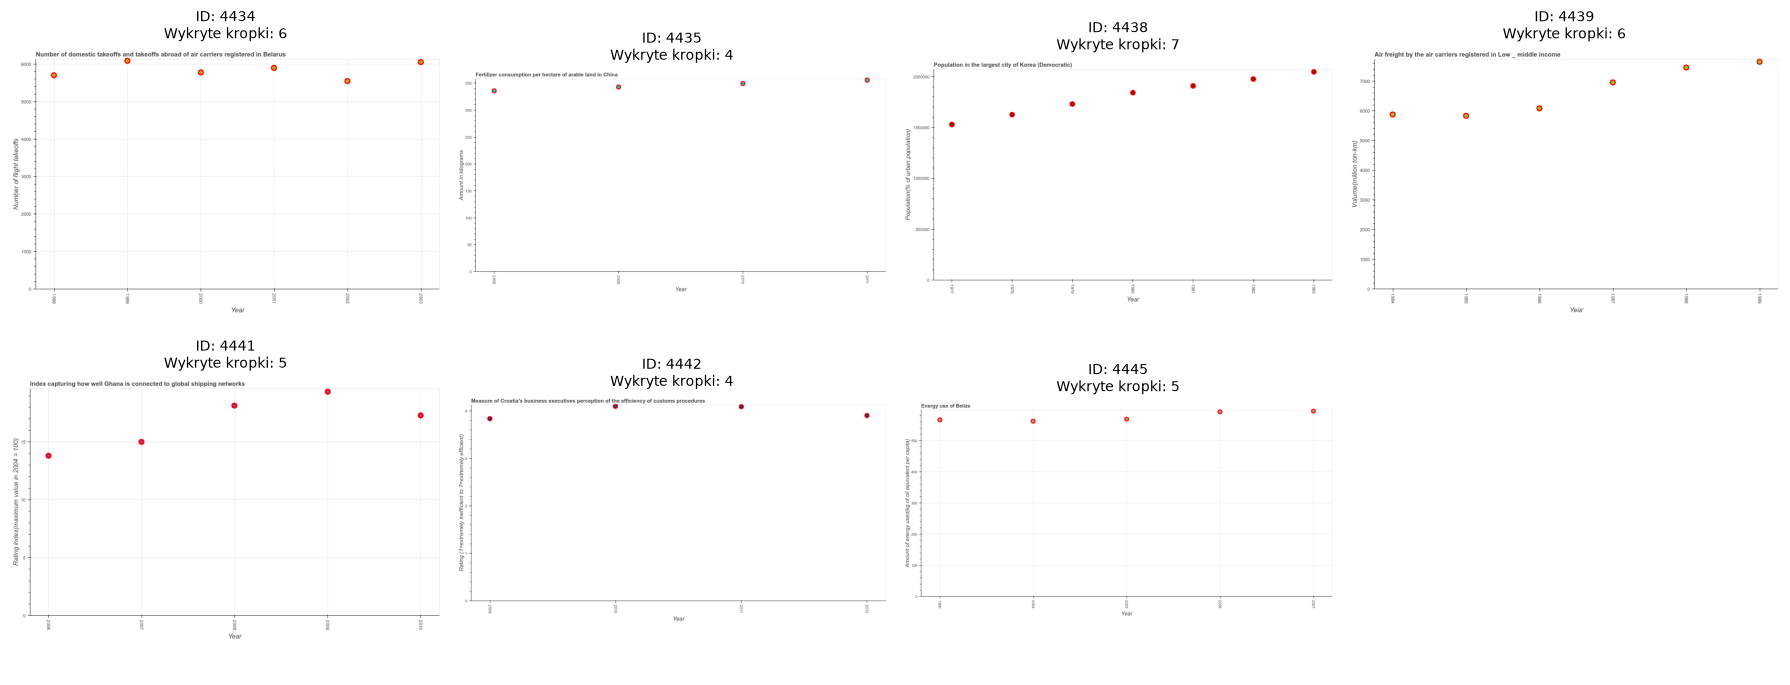

In [25]:
color_ids = [
    dev_id for dev_id in dev_ids if not is_monochrome(dev_images[dev_id])
]

rows, cols = 2, 4
fig, axes = plt.subplots(rows, cols, figsize=(18, 7))
axes = axes.flatten()

for i, dev_id in enumerate(color_ids):
    ax = axes[i]
    img = dev_images[dev_id].copy()

    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    sat = hsv[:, :, 1]

    _, thresh_sat = cv2.threshold(sat, 40, 255, cv2.THRESH_BINARY)

    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    thresh_clean = cv2.morphologyEx(
        thresh_sat, cv2.MORPH_OPEN, kernel, iterations=1
    )

    contours, _ = cv2.findContours(
        thresh_clean, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )
    detected_centers = []

    for c in contours:
        area = cv2.contourArea(c)
        perimeter = cv2.arcLength(c, True)

        if perimeter == 0:
            continue

        circularity = (4 * np.pi * area) / (perimeter**2)

        if 15 <= area <= 400 and circularity >= 0.40:
            M = cv2.moments(c)
            if M["m00"] != 0:
                cx = int(M["m10"] / M["m00"])
                cy = int(M["m01"] / M["m00"])
                detected_centers.append((cx, cy))

    for cx, cy in detected_centers:
        cv2.circle(img, (cx, cy), 6, (0, 0, 255), 2)
        cv2.circle(img, (cx, cy), 1, (0, 255, 0), -1)  

    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(
        f"ID: {dev_id}\nWykryte kropki: {len(detected_centers)}", fontsize=10
    )
    ax.axis("off")

for j in range(len(color_ids), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

tutaj obyło się bez większych problemów, bo tak na prawdę po wyciągnięciu kanału nasycenia, zostają widoczne same kropki, dzięki temu ze reszta elementów jest czarna

teraz przydaloby sie sprawdzic, jakie wspolrzedne program faktycznie wyciaga i porownac je z tymi faktycznymi z pliku JSON, stworzmy wstepna funkcje, ktora to bedzie robila.
Nastepnie porownamy wyniki z faktycznymi danymi i potem bedziemy dokonywac ewentualnych poprawek

In [26]:
def detect_dots(img):
    h, w, _ = img.shape
    detected_centers = []

    if not is_monochrome(img):
        hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
        sat = hsv[:, :, 1]

        _, thresh_sat = cv2.threshold(sat, 40, 255, cv2.THRESH_BINARY)
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
        thresh_clean = cv2.morphologyEx(
            thresh_sat, cv2.MORPH_OPEN, kernel, iterations=1
        )

        contours, _ = cv2.findContours(
            thresh_clean, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
        )

        for c in contours:
            area = cv2.contourArea(c)
            perimeter = cv2.arcLength(c, True)
            if perimeter == 0:
                continue

            circularity = (4 * np.pi * area) / (perimeter**2)

            if 15 <= area <= 400 and circularity >= 0.40:
                M = cv2.moments(c)
                if M["m00"] != 0:
                    cx = int(M["m10"] / M["m00"])
                    cy = int(M["m01"] / M["m00"])
                    detected_centers.append((cx, cy))
    else:
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        thresh = cv2.adaptiveThreshold(
            gray,
            255,
            cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
            cv2.THRESH_BINARY_INV,
            blockSize=15,
            C=3,
        )

        hor_kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (20, 1))
        horizontal_lines = cv2.morphologyEx(
            thresh, cv2.MORPH_OPEN, hor_kernel, iterations=1
        )
        y_indices, _ = np.where(horizontal_lines > 0)

        if len(y_indices) > 0:
            top_grid_y = np.min(y_indices)
            thresh[0 : max(0, top_grid_y - 2), :] = 0

            bottom_grid_y = np.max(y_indices)
            thresh[min(h, bottom_grid_y + 4) :, :] = 0

        ver_kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (1, 20))
        vertical_lines = cv2.morphologyEx(
            thresh, cv2.MORPH_OPEN, ver_kernel, iterations=1
        )
        _, x_indices = np.where(vertical_lines > 0)

        if len(x_indices) > 0:
            left_grid_x = np.min(x_indices)
            thresh[:, 0 : max(0, left_grid_x - 4)] = 0

        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
        thresh_clean = cv2.morphologyEx(
            thresh, cv2.MORPH_OPEN, kernel, iterations=1
        )

        contours, _ = cv2.findContours(
            thresh_clean, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
        )

        for c in contours:
            area = cv2.contourArea(c)
            perimeter = cv2.arcLength(c, True)
            if perimeter == 0:
                continue

            x, y, bw, bh = cv2.boundingRect(c)
            aspect_ratio = float(bw) / bh if bh > 0 else 0
            circularity = (4 * np.pi * area) / (perimeter**2)

            if (
                15 <= area <= 350
                and circularity >= 0.40
                and 0.65 <= aspect_ratio <= 1.45
            ):
                M = cv2.moments(c)
                if M["m00"] != 0:
                    cx = int(M["m10"] / M["m00"])
                    cy = int(M["m01"] / M["m00"])
                    detected_centers.append((cx, cy))

    detected_centers.sort(key=lambda p: p[0])
    return detected_centers

In [27]:
meta_path2 = os.path.join("..", "data", "sample_annotations.json")
with open(meta_path2, 'r', encoding='utf-8') as f:
    full_data = json.load(f)

dev_ids = full_data['dev_ids']

annot_dict = {str(sample["image_index"]): sample for sample in full_data["samples"]}

images_dir = os.path.join("..", "data", "sample_images")
dev_images = {
    idx: cv2.imread(os.path.join(images_dir, f"{idx}.png")) for idx in dev_ids
}

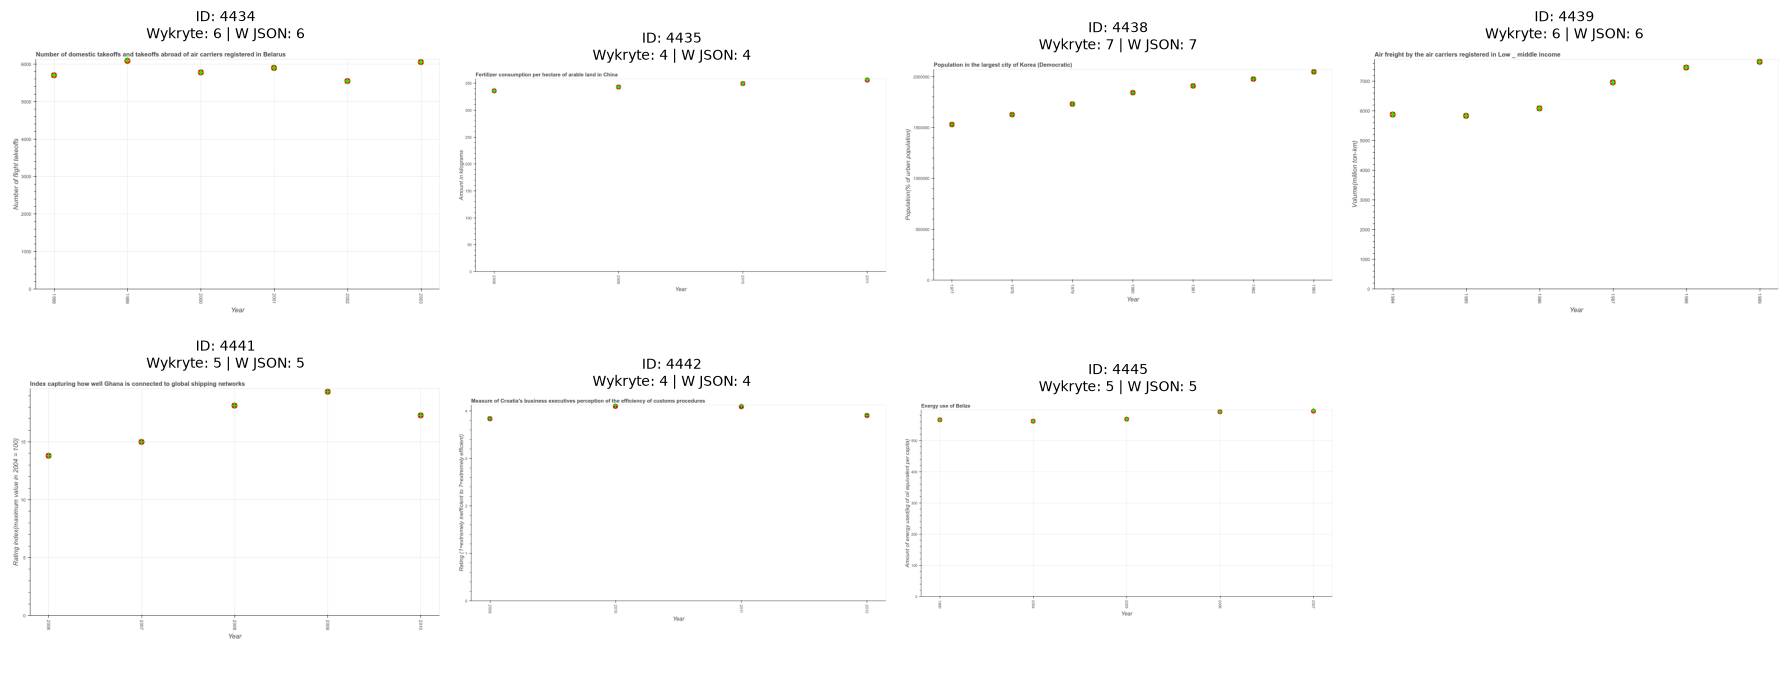

In [28]:
color_ids = [
    dev_id for dev_id in dev_ids if not is_monochrome(dev_images[dev_id])
]

rows, cols = 2, 4
fig, axes = plt.subplots(rows, cols, figsize=(18, 7))
axes = axes.flatten()

for i, dev_id in enumerate(color_ids[:rows * cols]):
    ax = axes[i]
    img = dev_images[dev_id].copy()

    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    sat = hsv[:, :, 1]

    _, thresh_sat = cv2.threshold(sat, 40, 255, cv2.THRESH_BINARY)

    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    thresh_clean = cv2.morphologyEx(
        thresh_sat, cv2.MORPH_OPEN, kernel, iterations=1
    )

    contours, _ = cv2.findContours(
        thresh_clean, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )
    detected_centers = []

    for c in contours:
        area = cv2.contourArea(c)
        perimeter = cv2.arcLength(c, True)

        if perimeter == 0:
            continue

        circularity = (4 * np.pi * area) / (perimeter**2)

        if 15 <= area <= 400 and circularity >= 0.40:
            M = cv2.moments(c)
            if M["m00"] != 0:
                cx = int(M["m10"] / M["m00"])
                cy = int(M["m01"] / M["m00"])
                detected_centers.append((cx, cy))

    gt_centers = []
    sample_annot = annot_dict.get(str(dev_id))
    if sample_annot and "models" in sample_annot:
        for model in sample_annot["models"]:
            if "bboxes" in model:
                for bbox in model["bboxes"]:
                    gt_cx = bbox["x"] + bbox["w"] / 2
                    gt_cy = bbox["y"] + bbox["h"] / 2
                    gt_centers.append((gt_cx, gt_cy))

    for cx, cy in detected_centers:
        cv2.circle(img, (cx, cy), 6, (0, 0, 255), 2)
        cv2.circle(img, (cx, cy), 1, (0, 255, 0), -1) 

    for gx, gy in gt_centers:
        cv2.drawMarker(img, (int(gx), int(gy)), (0, 255, 0), markerType=cv2.MARKER_CROSS, markerSize=12, thickness=2)

    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(
        f"ID: {dev_id}\nWykryte: {len(detected_centers)} | W JSON: {len(gt_centers)}", fontsize=10
    )
    ax.axis("off")

for j in range(len(color_ids[:rows * cols]), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

### OSTATECZNA ARCHITEKTURA DETEKTORA KROPEK ###

#### 1. klasyfikacja obrazu wejsciowego
Najpierw trzeba ocenić poziom nasycenia. Wykres będzie klasyfikowany na podstawie kanału nasycenia (Saturation) z HSV:
* **sciezka kolorowa:** wykresy posiadajace nasycone kropki
* **siezka monochromatyczna:** wykresy czarno-białe, lub w skali szarości


#### 2. ściezka kolorowa
Dla kolorowych wykresow problem izolacji kropek od czarnych osi, szarych linii siatki i tekstów jest rozwiązany od razu w przestrzeni barw:
1. **wyciągnięcie kanału S:** obraz BGR zostaje przekonwertowany do HSV, z którego pobierany jest kanał nasycenia ($S$)
2. **progowanie proste ('cv2.threshold'):** Odcinamy piksele o nasyceniu mniejszym niz $40$. Wtedy ciemny tekst, siatka i osie stają się czarne, a kolorowe kropki zostają białe
3. **filtracja morfologiczna ('cv2.MORPH_OPEN'):** zastosowanie elipsy $3 \times 3$, ktora wymazuje szum z tła
4. **wyznaczenie punktów ($cx, $cy$):** z wyciagnietych konturow odrzucamy obiekty, ktore nie miesza sie w przedziale powierzchni $15 \le \text{Area} \le 400$ lub mają kolowosc ponizej progu ($C \ge 0.40$). DLa zaakceptowanych konturow wyliczamy dokladne srodki ciezkosci $(cx, cy)$ za pomoca 'cv2.moments'


#### 3. sciezka monochromatyczna
Dla wykresow monochromatycznych, gdzie kropki, siatka i osie mają zblizona jasność, stosujemy potok opisany nizej:
1. **konwersja do skali szarości i binaryzacja adapcyjna:** obraz BGR zostaje przekonwertowany do GRAY, a nastepnie jest poddany progowaniu adaptycyjnemu ('cv2.adaptiveThreshold'), co zamienia czarne elementy w białe obiekty na czarnym tle
2. **wyznaczenie Dynamic ROI:**
    * **Wykrycie linii siatki i osi:** przejezdzamy po obrazie dlugimi paskami, zeby namierzyc skrajne linie wykresu
    * **Odcięcie nagłówka i dołu:** wszystko, co wystaje nad najwyzsza, oraz najnizsza linie (napisy, wartosci), wymazujemy
    * **Odcięcie lewego marginesu:** wymazujemy lewy margines przed osią Y, zeby pozbyc sie wartosci skali
3. **oczyszczenie wnetrza:** usuwamy pozostalosci po przecinajacych sie liniach siatki, za pomocą elipsy $3 \times 3$
4. **filtracja geometrii:** wykrywamy punkty z weryfikacją:
    * powierzchnia $15 \le \text{area} \le 350$ px
    * kołowość $C \ge 0.40$
    * proporcje boków: $0.65 \le \text{aspect ratio} \le 1.45$ (odrzucamy pozostalosci po cyfrach i liniach)
    * wyliczenie koncowych srodkow $(cx, cy)$ za pomocą 'cv2.moments'
